# 2章 評価ギャップ

## 事前準備

当サンプルコードを実行するには、OpenAIのAPIキーが必要です。

- OpenAIのプラットフォーム（ https://platform.openai.com/ ）にアクセスし、ご自身のアカウントでログインして、APIキーを生成してください。
- 生成したAPIキーを定数 `OPENAI_API_KEY` に設定します。

```
OPENAI_API_KEY=<作成したAPIキー>
```

In [ ]:
OPENAI_API_KEY="<作成したAPIキー>"

In [2]:
import os
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

In [3]:
!wget "https://drive.google.com/uc?export=download&id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_" -O apple.txt

--2026-10-22 05:27:55--  https://drive.google.com/uc?export=download&id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_
Resolving drive.google.com (drive.google.com)... 173.194.69.102, 173.194.69.113, 173.194.69.139, ...
Connecting to drive.google.com (drive.google.com)|173.194.69.102|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_&export=download [following]
--2026-10-22 05:27:55--  https://drive.usercontent.google.com/download?id=1QQlSIaCDIFql-IHBd9NHd3YiqTAN2gr_&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 192.178.156.132, 2a00:1450:4013:c1c::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|192.178.156.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 410321 (401K) [application/octet-stream]
Saving to: ‘apple.txt’

apple.txt           100%[===================>] 400.70K  --.-KB/s    

In [4]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.8 MB/s eta 0:00:00


In [5]:
!pip install rouge_score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=73b4d3ce0f915bea341d88dd7f3138586fe3ee22f40c09ef583f3e280b3e2076
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [6]:
MAX_LENGTH = 200_000
# 10-Kの本文が「apple.txt」というファイルに保存されているものとする
with open('apple.txt', 'r') as file:
    sec_filing = file.read()

sec_filing = sec_filing[:MAX_LENGTH]

In [7]:
from openai import OpenAI
client = OpenAI()

In [ ]:
def generate_responses(
    model_name: str,
    prompt: str,
    temperatures: List[float],
    attempts: int = 3
) -> pd.DataFrame:
    """
    異なる温度設定で複数の応答を生成し、
    非決定論的な挙動を実証する。
    """
    results = []
    # 温度のループ
    for temp in temperatures:
        for attempt in range(attempts):
            response = client.chat.completions.create(
                model=model_name,
                messages=[{"role": "user", "content": prompt}],
                temperature=temp,
                max_completion_tokens=50
            )

            results.append({
                'temperature': temp,
                'attempt': attempt + 1,
                'response': response.choices[0].message.content
            })

    # 温度ごとにグループ分けして結果を表示する
    df_results = pd.DataFrame(results)
    for temp in temperatures:
        print(f"\nTemperature = {temp}")
        print("-" * 40)
        temp_responses = df_results[df_results['temperature'] == temp]
        for _, row in temp_responses.iterrows():
            print(f"Attempt {row['attempt']}: {row['response']}")

    return df_results

df_results = generate_responses(model_name="gpt-4.1-mini",
                                prompt="Write a single-statement executive summary "
                                      f"of the following text: {sec_filing}",
                               temperatures=[0.0, 1.0, 2.0])


Temperature = 0.0
----------------------------------------
Attempt 1: Apple Inc. reported a 2% increase in net sales to $391 billion for fiscal year 2024, driven by growth in Services and Mac products despite declines in iPad and Wearables sales and challenges in Greater China, while maintaining strong profitability
Attempt 2: Apple Inc. reported a 2% increase in net sales to $391 billion for fiscal year 2024, driven by growth in Services and Mac products despite declines in Greater China and Wearables, while maintaining strong profitability with a net income of $
Attempt 3: Apple Inc. reported a 2% increase in net sales to $391 billion for fiscal year 2024, driven by growth in Services and Mac products despite declines in Greater China and Wearables, while maintaining strong profitability with a net income of $

Temperature = 1.0
----------------------------------------
Attempt 1: Apple Inc.’s 2024 fiscal year highlights include a 2% increase in net sales to $391 billion driven by gr

In [ ]:
import evaluate

def evaluate_summaries(generated_summary, reference_summary):
    """
    複数のメトリックを使用して、生成された要約を参照要約と比較して評価する。

    Args:
        generated_summary (str): モデルによって生成された要約
        reference_summary (str): 参照用の要約（正解）

    Returns:
        dict: 各メトリックのスコアを格納した辞書
    """
    # メトリックの初期化
    bleu = evaluate.load("google_bleu")
    rouge = evaluate.load("rouge")

    # BLEU用に入力を整形する
    # predictionsは文字列のリスト形式、
    # referencesは文字列のリストのリスト形式
    predictions = [generated_summary]
    references = [reference_summary]

    # BLEUのスコアを求める
    bleu_score = bleu.compute(
        predictions=predictions,
        references=[references]
    )

    # ROUGEのスコアを求める
    rouge_score = rouge.compute(
        predictions=predictions,
        references=references
    )

    # すべてのスコアを一つの辞書にまとめる
    scores = {
        'bleu': bleu_score["google_bleu"],
        'rouge1': rouge_score['rouge1'],
        'rouge2': rouge_score['rouge2']
    }

    return scores

In [ ]:
sentence1 = "the cat sat on the mat"
sentence2 = "the cat ate the mat"
evaluate_summaries(sentence1, sentence2)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{'bleu': 0.3333333333333333,
 'rouge1': np.float64(0.7272727272727272),
 'rouge2': np.float64(0.4444444444444445)}

In [ ]:
def generate_summary(model, input):
    """
    指定したモデルで入力テキストを要約する
    """
    TASK = """Generate a summary of approximately five sentences that explains several main points
    of the following excerpt from an SEC filing."""

    prompt = f"""
    ROLE: You are an expert analyst tasked with summarizing SEC filings.
    TASK: {TASK}
    """

    response = client.chat.completions.create(
        model=model,
        messages=[{"role": "system", "content": prompt},
                  {"role": "user", "content": input}]
    )
    return response.choices[0].message.content


def evaluate_summary_models(model_benchmark, models_test, input):
    """
    複数のモデルが生成した要約を評価する
    """
    benchmark_summary = generate_summary(model_benchmark, input)

    # リスト内包表記を使用して、すべてのテスト対象モデルの要約を生成する
    model_summaries = [generate_summary(model, input)
                       for model in models_test]

    # 各モデルの要約をベンチマークと比較して評価する
    evaluation_results = [evaluate_summaries(summary, benchmark_summary)
                          for summary in model_summaries]

    return [evaluation_results, model_summaries, benchmark_summary]

In [ ]:
model_benchmark = "gpt-5.5"
models_test = ["gpt-5.4", "gpt-5.4-mini", "gpt-4.1-mini"]

evals, model_summaries, benchmark_summary = evaluate_summary_models(
    model_benchmark,
    models_test,
    sec_filing
)

In [ ]:
benchmark_summary

'Apple’s fiscal 2024 Form 10-K describes the company as a global provider of iPhone, Mac, iPad, Wearables/Home/Accessories, and Services, managed primarily through geographic segments including the Americas, Europe, Greater China, Japan, and Rest of Asia Pacific. Net sales rose 2% to $391.0 billion in 2024, driven largely by 13% growth in Services, while iPhone sales were roughly flat, Mac sales increased modestly, and iPad and Wearables/Home/Accessories declined. Net income fell to $93.7 billion from $97.0 billion, primarily reflecting a higher effective tax rate caused by a one-time $10.2 billion net income tax charge related to the European Commission State Aid Decision. Apple continued significant capital returns, repurchasing about $95.0 billion of common stock and paying $15.2 billion in dividends and dividend equivalents, while reporting $140.8 billion in unrestricted cash, cash equivalents and marketable securities at year-end. The filing highlights major risks including macroe

In [ ]:
evals

[{'bleu': 0.38289205702647655,
  'rouge1': np.float64(0.6507177033492823),
  'rouge2': np.float64(0.37980769230769235)},
 {'bleu': 0.26834381551362685,
  'rouge1': np.float64(0.5858585858585859),
  'rouge2': np.float64(0.29441624365482233)},
 {'bleu': 0.2180293501048218,
  'rouge1': np.float64(0.5699208443271768),
  'rouge2': np.float64(0.1962864721485411)}]

In [ ]:
model_summaries

['Apple’s 2024 Form 10-K describes a business centered on hardware products such as iPhone, Mac, iPad, wearables and accessories, supported by a fast-growing services business that includes advertising, cloud, digital content, subscriptions and payments. For fiscal 2024, net sales rose 2% to $391.0 billion, driven mainly by 13% growth in Services to $96.2 billion, while iPhone sales were essentially flat and iPad and Wearables/Home/Accessories declined. Profitability improved at the gross margin level, with total gross margin rising to 46.2%, but net income fell to $93.7 billion because of a one-time $10.2 billion tax charge tied to the European Commission State Aid decision involving Ireland. The filing emphasizes major risks including intense competition, dependence on global suppliers and outsourcing partners, geopolitical and trade tensions, cybersecurity threats, changing regulation, and legal challenges such as EU Digital Markets Act investigations, the U.S. DOJ antitrust suit, a

In [ ]:
for model, summary in zip(models_test, model_summaries):
    print(f"{model}: \n {summary} \n---------------")

gpt-5.4: 
 Apple’s 2024 Form 10-K describes a business centered on hardware products such as iPhone, Mac, iPad, wearables and accessories, supported by a fast-growing services business that includes advertising, cloud, digital content, subscriptions and payments. For fiscal 2024, net sales rose 2% to $391.0 billion, driven mainly by 13% growth in Services to $96.2 billion, while iPhone sales were essentially flat and iPad and Wearables/Home/Accessories declined. Profitability improved at the gross margin level, with total gross margin rising to 46.2%, but net income fell to $93.7 billion because of a one-time $10.2 billion tax charge tied to the European Commission State Aid decision involving Ireland. The filing emphasizes major risks including intense competition, dependence on global suppliers and outsourcing partners, geopolitical and trade tensions, cybersecurity threats, changing regulation, and legal challenges such as EU Digital Markets Act investigations, the U.S. DOJ antitrus

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.ticker import MaxNLocator
def visualize_prompt_comparison(evaluation_results, model_names):
    """
    複数のメトリックのバリエーションを比較するレーダープロットを作成する

    Args:
        evaluation_results (list): 評価結果を格納した辞書のリスト
        model_names (list): モデル名のリスト
    """

    # 可視化用にデータを整形する
    labels = list(evaluation_results[0].keys())
    num_vars = len(labels)

    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"polar": True})
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=18)
    ax.tick_params(axis="x", pad=10)

    max_value = max(max(result[label] for label in labels) for result in evaluation_results)
    r_max = max_value * 1.15
    ax.set_ylim(0, r_max)

    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_rlabel_position(45)
    ax.tick_params(axis="y", labelsize=16)

    # モデルごとに描画
    for result, model_name in zip(evaluation_results, model_names):
        values = [result[label] for label in labels]
        closed_values = values + values[:1]

        line, = ax.plot(angles, closed_values, linewidth=2, label=model_name)
        ax.fill(angles, closed_values, alpha=0.10, color=line.get_color())

    ax.legend(
        loc="upper left",
        fontsize=16,
        bbox_to_anchor=(0.90, 1.05),
        frameon=False
    )

    plt.subplots_adjust(left=0.16, right=0.78, top=0.92, bottom=0.08)


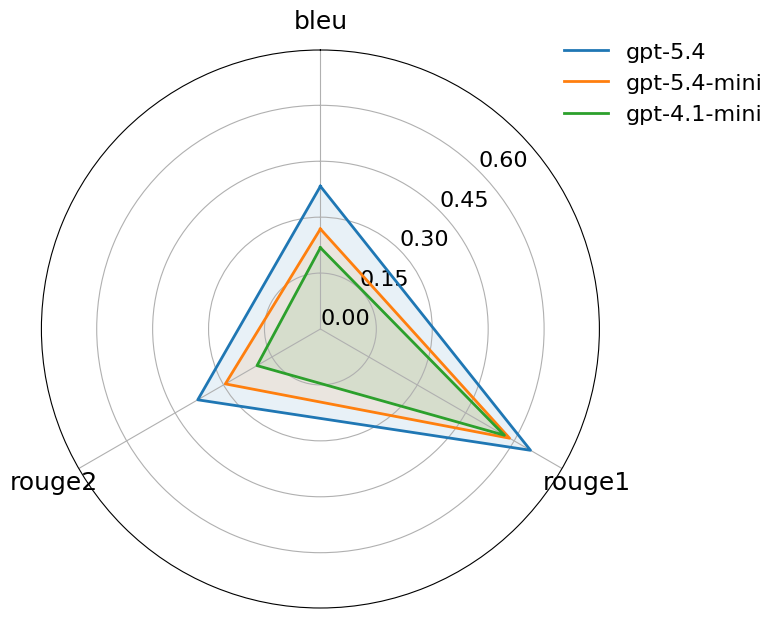

In [ ]:
# プロットを表示する
visualize_prompt_comparison(evals, models_test)
plt.show()

In [ ]:
from pydantic import BaseModel
from typing import List, Dict

class JudgeEvaluation(BaseModel):
    expertise: int
    coherence: int
    fluency: int
    similarity: int

def evaluate_with_llm(judge_model: str, candidate_summary: str,
                      reference_summary: str) -> Dict[str, float]:
    """
    LLMを使用して、候補要約を参照要約と比較して評価する。

    Args:
        judge_model (str): 評価に使用するモデルの名前
        candidate_summary (str): 評価対象となる生成済みの要約
        reference_summary (str): ベンチマークとなる要約（正解）

    Returns:
        dict: 評価スコアを格納した辞書
    """
    prompt = f"""
    ROLE: You are an expert evaluator of SEC filing summaries.
    Evaluate the following candidate summary against the reference
    summary on a scale of 1 to 10 for the following criteria:
    - Expertise: Does the summary look like it was written by an expert
    analyst?
    - Coherence: Is the candidate summary logically organized and easy to
    understand?
    - Fluency: Is the language of the candidate summary clear and
    grammatically correct?
    - Similarity: How similar is the candidate summary compared to the
    reference summary?

    Reference Summary:
    "{reference_summary}"

    Candidate Summary:
    "{candidate_summary}"

    Provide scores in this format:
    Expertise: X, Coherence: Y, Fluency: Z, Similarity: W
    """
    completion = client.beta.chat.completions.parse(
        model=judge_model,
        messages=[{"role": "system", "content": prompt}],
        response_format=JudgeEvaluation
    )
    return completion.choices[0].message.parsed

def evaluate_summary_models_with_judge(
    judge_model: str,
    benchmark_model: str,
    test_models: List[str],
    input_text: str):
    """
    LLM-as-a-judgeアプローチを用いて、複数のモデルが生成した要約を評価する。

    Args:
        judge_model (str): 評価に使用するモデルの名前
        benchmark_model (str): ベンチマークとして使用するモデルの名前
        test_models (list): テスト対象となるモデル名のリスト
        input_text (str): 要約対象となる入力テキスト

    Returns:
        tuple: 評価結果、各モデルの要約、ベンチマーク要約
    """

    benchmark_summary = generate_summary(benchmark_model, input_text)
    model_summaries = [
        generate_summary(model, input_text) for model in test_models
    ]

    evaluation_results = [
        evaluate_with_llm(judge_model, summary, benchmark_summary)
        for summary in model_summaries
    ]

    return evaluation_results, model_summaries, benchmark_summary

In [ ]:
model_benchmark = "gpt-5.5"
models_test = ["gpt-5.4", "gpt-5.4-mini", "gpt-4.1-mini"]
judge_model = "gpt-5.5"

evals, model_summaries, benchmark_summary = evaluate_summary_models_with_judge(
    judge_model, model_benchmark, models_test, sec_filing
)

In [ ]:
benchmark_summary

'Apple’s fiscal 2024 Form 10-K describes the company as a global designer, manufacturer and seller of iPhone, Mac, iPad, wearables, accessories and services, managed primarily through geographic segments: Americas, Europe, Greater China, Japan and Rest of Asia Pacific. Total net sales rose 2% to $391.0 billion, driven by 13% growth in Services to $96.2 billion, while iPhone sales were roughly flat, Mac sales increased modestly, and iPad and Wearables/Home/Accessories declined. Net income decreased to $93.7 billion from $97.0 billion, largely reflecting a higher effective tax rate due to a $10.2 billion net one-time income tax charge related to the European Commission State Aid Decision, though gross margin improved to 46.2%. Apple highlighted major risks including macroeconomic weakness, intense competition, reliance on global suppliers and outsourcing partners, component shortages, cybersecurity threats, regulatory scrutiny, antitrust actions, and App Store-related legal and regulator

In [ ]:
model_summaries

['Apple’s 2024 Form 10-K describes a business centered on hardware products like iPhone, Mac, iPad, wearables and accessories, alongside a fast-growing Services segment that includes the App Store, cloud, subscriptions, advertising and payments. For fiscal 2024, net sales rose 2% to $391.0 billion, driven mainly by 13% growth in Services to $96.2 billion, while iPhone sales were essentially flat and iPad and Wearables/Home/Accessories declined; geographically, Europe, the Americas and Japan grew, but Greater China sales fell 8%. Profitability improved at the gross margin level, with total gross margin rising to 46.2%, but net income declined to $93.7 billion largely because Apple recorded a one-time $10.2 billion tax charge tied to the European Commission State Aid Decision in Ireland. The filing emphasizes major risks including intense competition, dependence on global suppliers and outsourcing partners concentrated in Asia, macroeconomic and geopolitical pressures, component shortage

In [ ]:
evals

[JudgeEvaluation(expertise=10, coherence=10, fluency=10, similarity=9),
 JudgeEvaluation(expertise=9, coherence=9, fluency=10, similarity=8),
 JudgeEvaluation(expertise=8, coherence=9, fluency=9, similarity=8)]

In [ ]:
# 評価結果のオブジェクトを辞書に変換する
evals_list = [
    {
        "expertise": e.expertise,
        "coherence": e.coherence,
        "fluency": e.fluency,
        "similarity": e.similarity
    }
    for e in evals
]

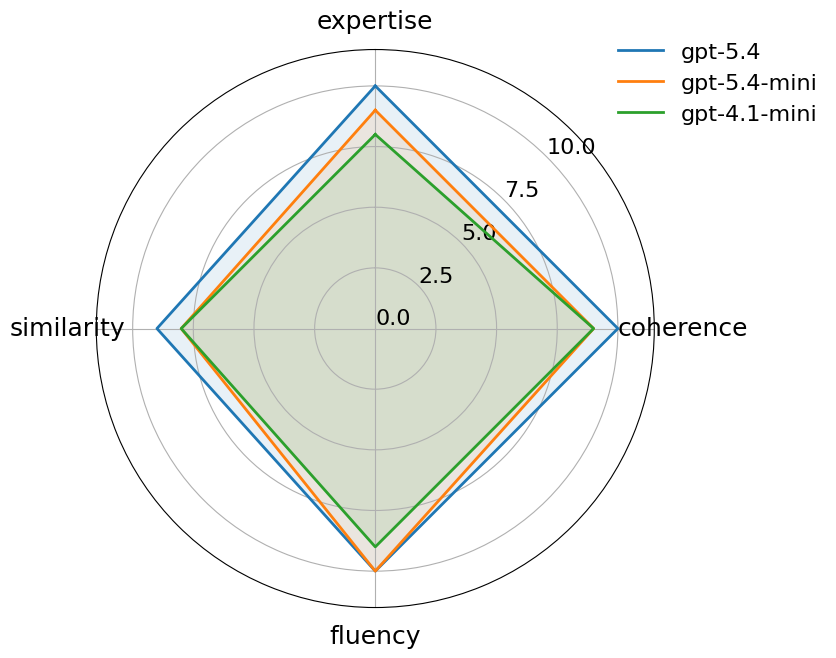

In [ ]:
# 結果を可視化する
visualize_prompt_comparison(evals_list, models_test)
plt.show()